# **TP3 - Redes Neuronales**
## Redes Neuronales Convolucionales (CNN)
#### Dataset: Dogs vs Cats

------------------------
------------------------
**Instrucciones:**

- **No** modificar las celdas de texto.

- Resolver cada consigna en su sección correspondiente. Pueden sumar celdas de código y texto si lo consideran necesario. Recuerden que lo más importante es el razonamiento y justificación de los pasos para demostrar comprensión del problema a resolver.

- **ENTREGA:** Ir a Archivo > Descargar .ipynb. Este archivo .ipynb deberán subirlo al campus junto con las diapositivas en formato PDF (archivo no editable) hasta las 23:59hs del día anterior a la presentación. La presentación oral de este último documento será de manera grupal en hasta 10 minutos  durante el horario de clase (anunciaremos el orden de los grupos en el campus).

------------------------
------------------------

# **Objetivo:** Entrenar una CNN para clasificación binaria entre gatos y perros

El dataset que usaremos fue armado para una competencia de Kaggle en 2013, donde se premiaba al mejor modelo capaz de distinguir entre fotos de gatos y perros. Los modelos ganadores alcanzaron una accuracy de ~95%.

# En caso de sobre carga de la notebook
En caso de experimentar una sobrecarga de memoria durante la ejecución de la notebook, o si Google Colab se desconecta debido al uso excesivo de RAM o GPU, se recomienda probar alguna de las siguientes estrategias:



*   Reducir el tamaño del batch_size, por ejemplo de 64 a 32 o 16 especialmente durante el entrenamiento de modelos más pesados.
* Reducir la cantidad de hiperparámetros evaluados o limitar el número de combinaciones probadas.
* Utilizar métodos de búsqueda más eficientes, como Bayesian Optimization, en lugar de una búsqueda exhaustiva tipo Grid Search. (ver codigo al final de la NoteBook en la seccion "Ayuda")
* Reducir la cantidad máxima de épocas durante la búsqueda de hiperparámetros y utilizar EarlyStopping para detener el entrenamiento cuando el modelo deja de mejorar.

**Tambien pueden:**

* Liberar memoria entre distintos entrenamientos, eliminando modelos que ya no sean necesarios y utilizando tf.keras.backend.clear_session() cuando corresponda.

* Evitar mantener simultáneamente múltiples copias del dataset en memoria, por ejemplo una versión uint8 y otra versión normalizada en float32.

* Utilizar datos en formato float32 en lugar de formatos de mayor precisión, siempre que sea compatible con el modelo.
X = np.array(X, dtype=np.uint8) --> X = np.array(X, dtype=np.float32)

* Como alternativa más eficiente, trabajar directamente con los paths de las imágenes y cargarlas por lotes durante el entrenamiento utilizando tf.data.Dataset, en lugar de cargar todas las imágenes simultáneamente en memoria.(ver codigo al final de la NoteBook en la seccion "Ayuda")

Si el problema ocurre principalmente en la GPU, reducir además la resolución de las imágenes o el tamaño del batch.

Estas modificaciones permiten reducir considerablemente el consumo de memoria sin modificar de manera sustancial el objetivo del trabajo práctico.

## Carga de datos y pre-procesado

El dataset original tiene 25.000 imágenes. Acá trabajaremos con un subset de 12500 imágenes, que las subimos a github así lo cargan facilmente.

Trabajaremos con el siguiente split:
- Train: 9500
- Validation: 1000
- Test: 2000

In [ ]:
!git clone https://github.com/yohanncorfdir/SIA22.71

Cloning into 'SIA22.71'...
remote: Enumerating objects: 13005, done.
remote: Total 13005 (delta 0), reused 0 (delta 0), pack-reused 13005 (from 1)
Receiving objects: 100% (13005/13005), 402.81 MiB | 16.07 MiB/s, done.
Resolving deltas: 100% (11/11), done.
Updating files: 100% (13002/13002), done.


In [ ]:
import os
import cv2
import numpy as np
from sklearn.utils import shuffle

data_root = "/content/SIA22.71/PetImages"
classes = ["Cat", "Dog"]

# El dataset original tiene imágenes de distintos tamaños en formato JPG
size = (128, 128) # Vamos a redimensionar las imagenes a 128x128

X = []
y = []

for label, cls in enumerate(classes):
    folder = os.path.join(data_root, cls)
    files = sorted([f for f in os.listdir(folder) if f.lower().endswith(".jpg")])

    for filename in files:
        path = os.path.join(folder, filename)
        img = cv2.imread(path)
        if img is None:
            continue
        img = cv2.resize(img, dsize = size)
        X.append(img)
        y.append(label)  # Etiqueta 0 para gatos, 1 para perros
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

# Shuffle dataset
X, y = shuffle(X, y, random_state=42)

X_train, y_train = X[:9500], y[:9500]
X_val, y_val = X[9500:10500], y[9500:10500]
X_test, y_test = X[10500:12500], y[10500:12500]

print(f"Train:\t\t {len(X_train)} images")
print(f"Validation:\t {len(X_val)} images")
print(f"Test:\t\t {len(X_test)} images")
print(f"Image shape:\t {X_train[0].shape}")

Train:		 9500 images
Validation:	 1000 images
Test:		 2000 images
Image shape:	 (128, 128, 3)


Algunas imágenes de ejemplo:

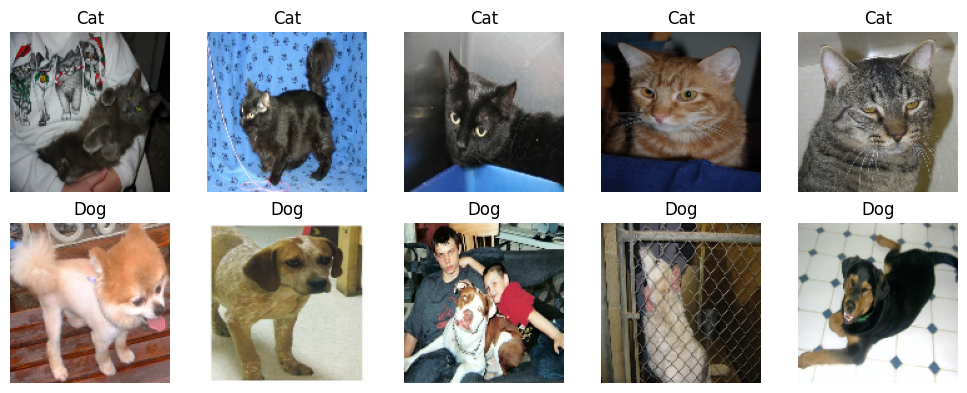

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i in range(5):
  #Las imágenes están guardadas en formato BGR. Para visualizarlas correctamente, las convertimos al formato RGB utilizando la función "cv2.COLOR_BGR2RGB".
    axes[0, i].imshow(cv2.cvtColor(X_train[y_train==0][i], cv2.COLOR_BGR2RGB))
    axes[0, i].set_title("Cat")
    axes[0, i].axis('off')
    axes[1, i].imshow(cv2.cvtColor(X_train[y_train==1][i], cv2.COLOR_BGR2RGB))
    axes[1, i].set_title("Dog")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

# Lineamiento general:
Para este último TP daremos lineamientos más generales, confiamos en que ya conocen el *workflow* del aprendizaje automático. Este dataset no requiere practicamente exploración/limpieza y ya está casi listo para entrenar. Además ya les damos los splits armados. Mantengan el código simple y limpio, deberían poder hacer todo con las herramientas vistas en las notebooks de las clases.

Los requerimientos que hay que cumplir son:
### 1) Un modelo inicial
### 2) Un modelo con data augmentation
### 3) Un modelo con transfer learning
### 4) Probar su sistema en datos propios

## 1) Modelo inicial:
*  Entrenar una CNN para clasificar las fotos de perros y gatos. Explicar claramente qué entra a la red, qué sale, cuales son las capas y qué hace cada una. Justificar la elección de las funciones de costo, activaciones interna y activación de salida.
*   Optimizar la arquitectura red dentro de lo posible, explicando el método de optimización utilizado y el espacio de búsqueda. Reportar la arquitectura final de la red y cantidad de parámetros.
*   Para el modelo final, reportar claramente los resultados en el conjunto de test.
*   Visualizar los feature maps creados por la primera capa del modelo para alguna imagen de un perro y una de un gato.

In [ ]:
# Código parte 1

## 2) Modelo con data augmentation:

El *data augmentation* es una técnica que incrementa artificialmente la cantidad y diversidad
de los datos de entrenamiento generando versiones modificadas de las imágenes existentes.
Su objetivo principal es mejorar la generalización del modelo y reducir el sobreajuste
(*overfitting*), siendo especialmente útil cuando el conjunto de datos es limitado.

Para imágenes, las transformaciones más comunes incluyen rotaciones, zoom, traslaciones,
recortes, volteos horizontales y cambios de brillo, entre otras.
*   Incorporar data augmentation a su pipeline de entrenamiento. Justificar qué transformaciones eligieron y por qué tienen sentido para este dataset en particular.
*   Comparar el rendimiento del modelo con y sin data augmentation sobre el conjunto de validación y testeo. ¿Se observa una reducción del overfitting en las curvas de entrenamiento?

In [ ]:
# Código parte 2

## 3) Modelo con Transfer Learning

El Transfer Learning consiste en reutilizar un modelo que ya fue entrenado previamente sobre un conjunto de datos grande y adaptarlo a un nuevo problema. De esta forma, podemos aprovechar representaciones visuales que la red ya aprendió, como la detección de bordes, texturas, formas y patrones más complejos.

La idea general puede representarse como:

**Modelo preentrenado → extracción de características → entrenar nuevas capas de clasificación → nueva tarea**.
Van a tener que utilizar una **ResNet50 preentrenada sobre ImageNet** y reemplazar la estructura necesaria para nuestra tarea. Dejen la ResNet50 congelada, entrenen solo un clasificador a partir de las caracterísiticas extraídas de ResNet50.

In [ ]:
# Código parte 3


## 4) Prueben su sistema en datos propios

*  Utilicen una o varias fotos de sus mascotas para probar con los modelos 2) y 3).
Si no tienen imágenes de mascotas, pueden usar de internet, o, incluso, probar con fotos de otros animales o sus dibujos de gatos/perros

In [ ]:
# Código parte 4

#Ayuda

Aquí van a poder encontrar código que puede ayudarlos con el TP.

La primera celda permite utilizar una búsqueda bayesiana en caso de que Grid Search o Randomized Search saturen la memoria.

La segunda celda permite cargar únicamente los paths de las imágenes al inicio, en lugar de cargar todas las imágenes en memoria. De esta manera, el procesamiento resulta menos pesado y se reduce el consumo de RAM.

In [ ]:
#Utilizacion de Bayesian para la busqueda de hiperparametros
#Optuna utiliza los resultados de los experimentos anteriores para decidir qué valores probar después
!pip install --quiet optuna
import optuna

def objective(trial):

    learning_rate = trial.suggest_float("learning_rate",1e-5,1e-2,log=True)

    dropout = trial.suggest_float("dropout",0.2,0.5)

    batch_size = trial.suggest_categorical("batch_size",[16, 32])

    filters = trial.suggest_categorical("filters",[32, 64, 128])

    model = create_model(
        learning_rate=learning_rate,
        dropout=dropout,
        filters=filters
    )

    history = model.fit(
        X_train,
        y_train,
        batch_size=batch_size,
        epochs=10,
        validation_data=(X_val, y_val),
        verbose=0
    )

    return max(history.history["val_accuracy"])


study = optuna.create_study(direction="maximize")

study.optimize(objective,n_trials=20)

print("Mejores parámetros:")
print(study.best_params)

print("Mejor accuracy:")
print(study.best_value)

In [ ]:
## Codigo para cargar los paths y no las imagenes en si
import os
import tensorflow as tf
from sklearn.model_selection import train_test_split

# Ruta principal del dataset
data_root = "/content/SIA22.71/PetImages"

classes = ["Cat", "Dog"]
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# En lugar de cargar todas las imágenes en memoria, guardamos únicamente la ruta de cada imagen y su etiqueta.
image_paths = []
labels = []
invalid_images = []

#Funcion para verificar si las imagenes tienen un formato correcto o si tenemos que descartarlas
def is_valid_image(path):
    try:
        image_bytes = tf.io.read_file(path)

        image = tf.image.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )

        # Forzar la evaluación para detectar errores
        _ = image.numpy()

        return True

    except Exception:
        return False

for label, cls in enumerate(classes):
    folder = os.path.join(data_root, cls)
    files = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith(".jpg")
    ])

    for filename in files:
        path = os.path.join(folder, filename)
        if is_valid_image(path):
            image_paths.append(path)
            labels.append(label)

        else:
            invalid_images.append(path)


print("Cantidad total de imágenes válidas:", len(image_paths))
print("Cantidad total de imágenes inválidas:", len(invalid_images))

if len(image_paths) == 0:
    raise ValueError(
        "No se encontró ninguna imagen válida. "
        "Verifica la ruta del dataset y el formato de los archivos."
    )

# Primero separamos 3000 imágenes para validación + test. El resto se utiliza para entrenamiento.
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=3000,
    random_state=42,
    stratify=labels
)


#3000 imágenes: 1000 validación, 2000 test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=2000,
    random_state=42,
    stratify=y_temp
)

#Funcion para cargar una imagen
def load_image(path, label):
    # Leer el archivo desde el disco
    image = tf.io.read_file(path)
    # Decodificar la imagen JPG directamente en formato RGB.
    image =  tf.image.decode_image(image,channels=3,expand_animations=False)

    # Redimensionar la imagen a 128x128
    image = tf.image.resize(image,IMG_SIZE)

    # Convertir la imagen a float32
    image = tf.cast(image,tf.float32)

    # Normalizar los valores de los píxeles
    image = image / 255.0

    # Convertir también la etiqueta a float32
    # para clasificación binaria.
    label = tf.cast(label,tf.float32)

    return image, label


#Dataset de entrenamiento
#Las imagenes todavia NO estan cargadas completamente en memoria.
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))

# Pipeline de entrenamiento
train_dataset = (
    train_dataset
    # Mezclar las imagenes
    .shuffle(buffer_size=1000, reshuffle_each_iteration=True)
    # Cargar las imagenes
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    # Agrupar las imagenes en batches
    .batch(BATCH_SIZE)
    # Preparar el siguiente batch mientras el modelo procesa el batch actual.
    .prefetch(tf.data.AUTOTUNE)
)


#Dataset Validacion
val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val))

val_dataset = (
    val_dataset
    # Cargar y preprocesar las imágenes
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    # Crear batches
    .batch(BATCH_SIZE)
    # Preparar batches de manera anticipada
    .prefetch(tf.data.AUTOTUNE)
)


#DataSet Test
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test))

test_dataset = (
    test_dataset
    # Cargar y preprocesar las imágenes
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    # Crear batches
    .batch(BATCH_SIZE)
    # Preparar el siguiente batch
    .prefetch(tf.data.AUTOTUNE)
)
